We try to approximate the $\mathrm{VIX}$ in the QRH model.

In [43]:
%config InlineBackend.figure_format='retina'

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import integrate, stats

from fwd_var_curve import xi_curve_smooth
from qrheston import QuadraticRoughHeston
from utils import plot_ivols_mc, var_swap_robust


sns.set_theme("talk")

Load market data and set initial forward variance curve

In [26]:
df_spx = pd.read_csv("spx_implied_vol_20230215.csv", index_col=0)
df_vix = pd.read_csv("vix_implied_vol_20230215.csv", index_col=0)
df_spx["Texp_days"] = (365.25 * df_spx["Texp"]).round().astype(int)
df_vix["Texp_days"] = (365.25 * df_vix["Texp"]).round().astype(int)
res_vs = var_swap_robust(ivol_data=df_spx)
w_in = res_vs["vs_mid"] * res_vs["expiries"]
xi_smooth = xi_curve_smooth(res_vs["expiries"], w_in, eps=0.03)["xi_curve"]

/Users/florianbourgey/projects/QuadraticRoughHeston/utils.py:156: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  wbar_flat = quad(PchipInterpolator(np.sort(y_in), sig_in_y**2), y_min, y_max)[0]


In [27]:
spx_expiries_days = [7, 14, 20, 28]
spx_expiries = np.array(spx_expiries_days) / 365.25

vix_expiries_days = [7, 14, 20, 28]
vix_expiries = np.array(vix_expiries_days) / 365.25

Set QRH parameters

In [28]:
params0 = {"al": 0.568, "lam": 9.68, "nu": 0.572, "c": 8.1e-3}
qrh = QuadraticRoughHeston(**params0, xi0=xi_smooth)

In [29]:
paths = 1 * 10**5
steps = 300
qrh_sim = qrh.simulate(paths=paths, steps=steps, expiries=spx_expiries, output="all")

### Trying to fit a shifted lognormal

Let $X \sim \exp\big\{ \mathcal{N}(\mu,\sigma^2) \big\} + \delta$ where $\delta \in \mathbb{R}$ is a shift parameter. The PDF of $X$ is 

$$
    f_{X}(x;\mu,\sigma,\delta)
    =
    \frac{1}{(x - \delta) \sigma \sqrt{2\pi}} \exp\left(-\frac{(\ln(x - \delta) - \mu)^2}{2\sigma^2}\right),
    \qquad
    \forall x \geq \delta.
$$

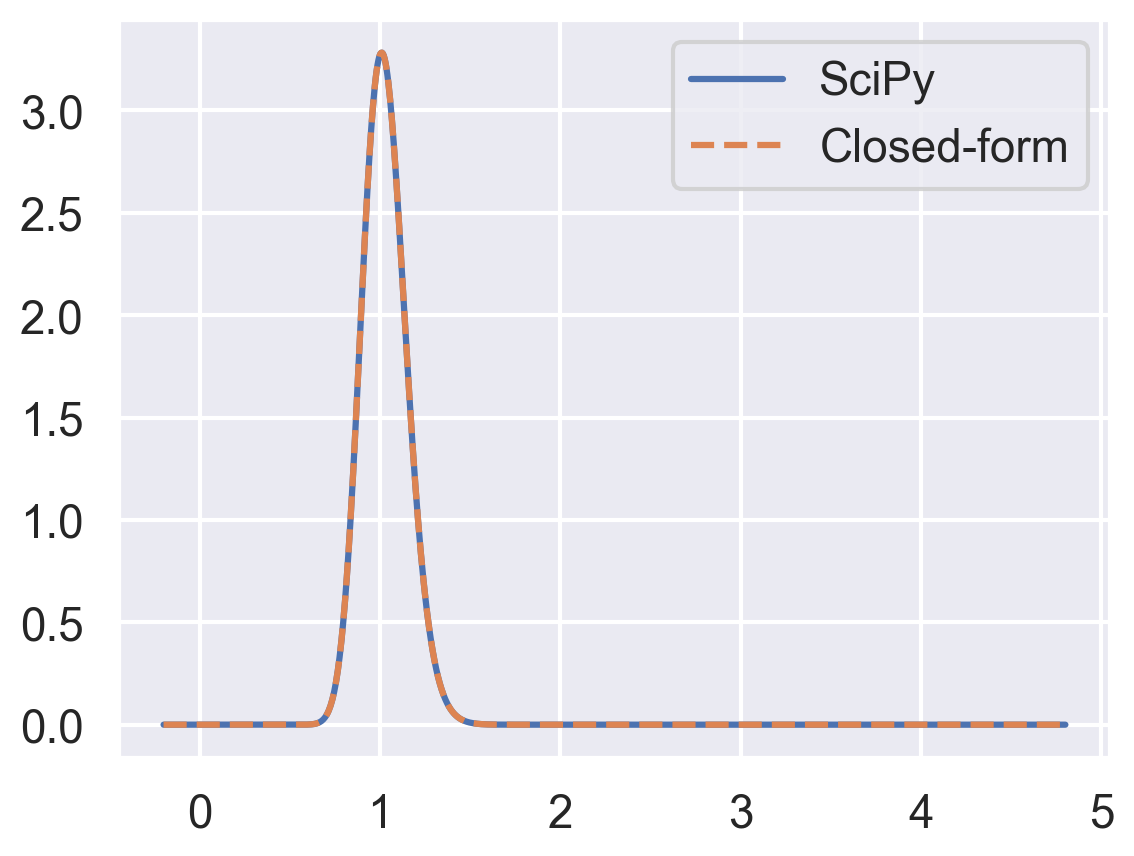

In [63]:
# Check PDF formula


def f_pdf(x, mu, sigma, delta):
    x = np.asarray(np.atleast_1d(x))
    pdf = np.zeros_like(x)
    mask = x > delta
    x_scaled = (np.log(x[mask] - delta) - mu) / sigma
    pdf[mask] = np.exp(-0.5 * x_scaled**2) / (
        (x[mask] - delta) * sigma * np.sqrt(2 * np.pi)
    )
    return pdf


mu = 0.2
sigma = 1e-1
shift = -0.2
xs = np.linspace(shift, shift + 5.0, 1000)
stats.lognorm.pdf(xs, s=sigma, scale=np.exp(mu), loc=shift)

fig, ax = plt.subplots()
ax.plot(
    xs,
    stats.lognorm.pdf(xs, s=sigma, scale=np.exp(mu), loc=shift),
    label="SciPy",
)
ax.plot(xs, f_pdf(xs, mu, sigma, shift), label="Closed-form", linestyle="--")
ax.legend()
plt.show()

In [64]:
# Sanity check: example on simulated data

true_mean, true_sigma, true_shift = 1.0, 0.5, 2.0
size = 10**5
data = np.exp(true_mean + true_sigma * np.random.randn(size)) + true_shift

# Fit shifted log normal
sigma, shift, scale = stats.lognorm.fit(data)

In [65]:
print("Fitted parameters:")
print(f"  Shape (sigma): {sigma:<.4f}  | {true_sigma:<.4f} (true)")
print(f"  Location (shift): {shift:<.4f}  | {true_shift:<.4f} (true)")
print(f"  Scale (scale): {scale:<.4f}  | {np.exp(true_mean):<.4f} (true)")

Fitted parameters:
  Shape (sigma): 0.5033  | 0.5000 (true)
  Location (shift): 2.0077  | 2.0000 (true)
  Scale (scale): 2.7065  | 2.7183 (true)


In [66]:
# grid for plotting
x_grid = np.linspace(min(data), max(data), 301)
# fitted pdf
pdf_vals = stats.lognorm.pdf(x_grid, s=sigma, scale=scale, loc=shift)

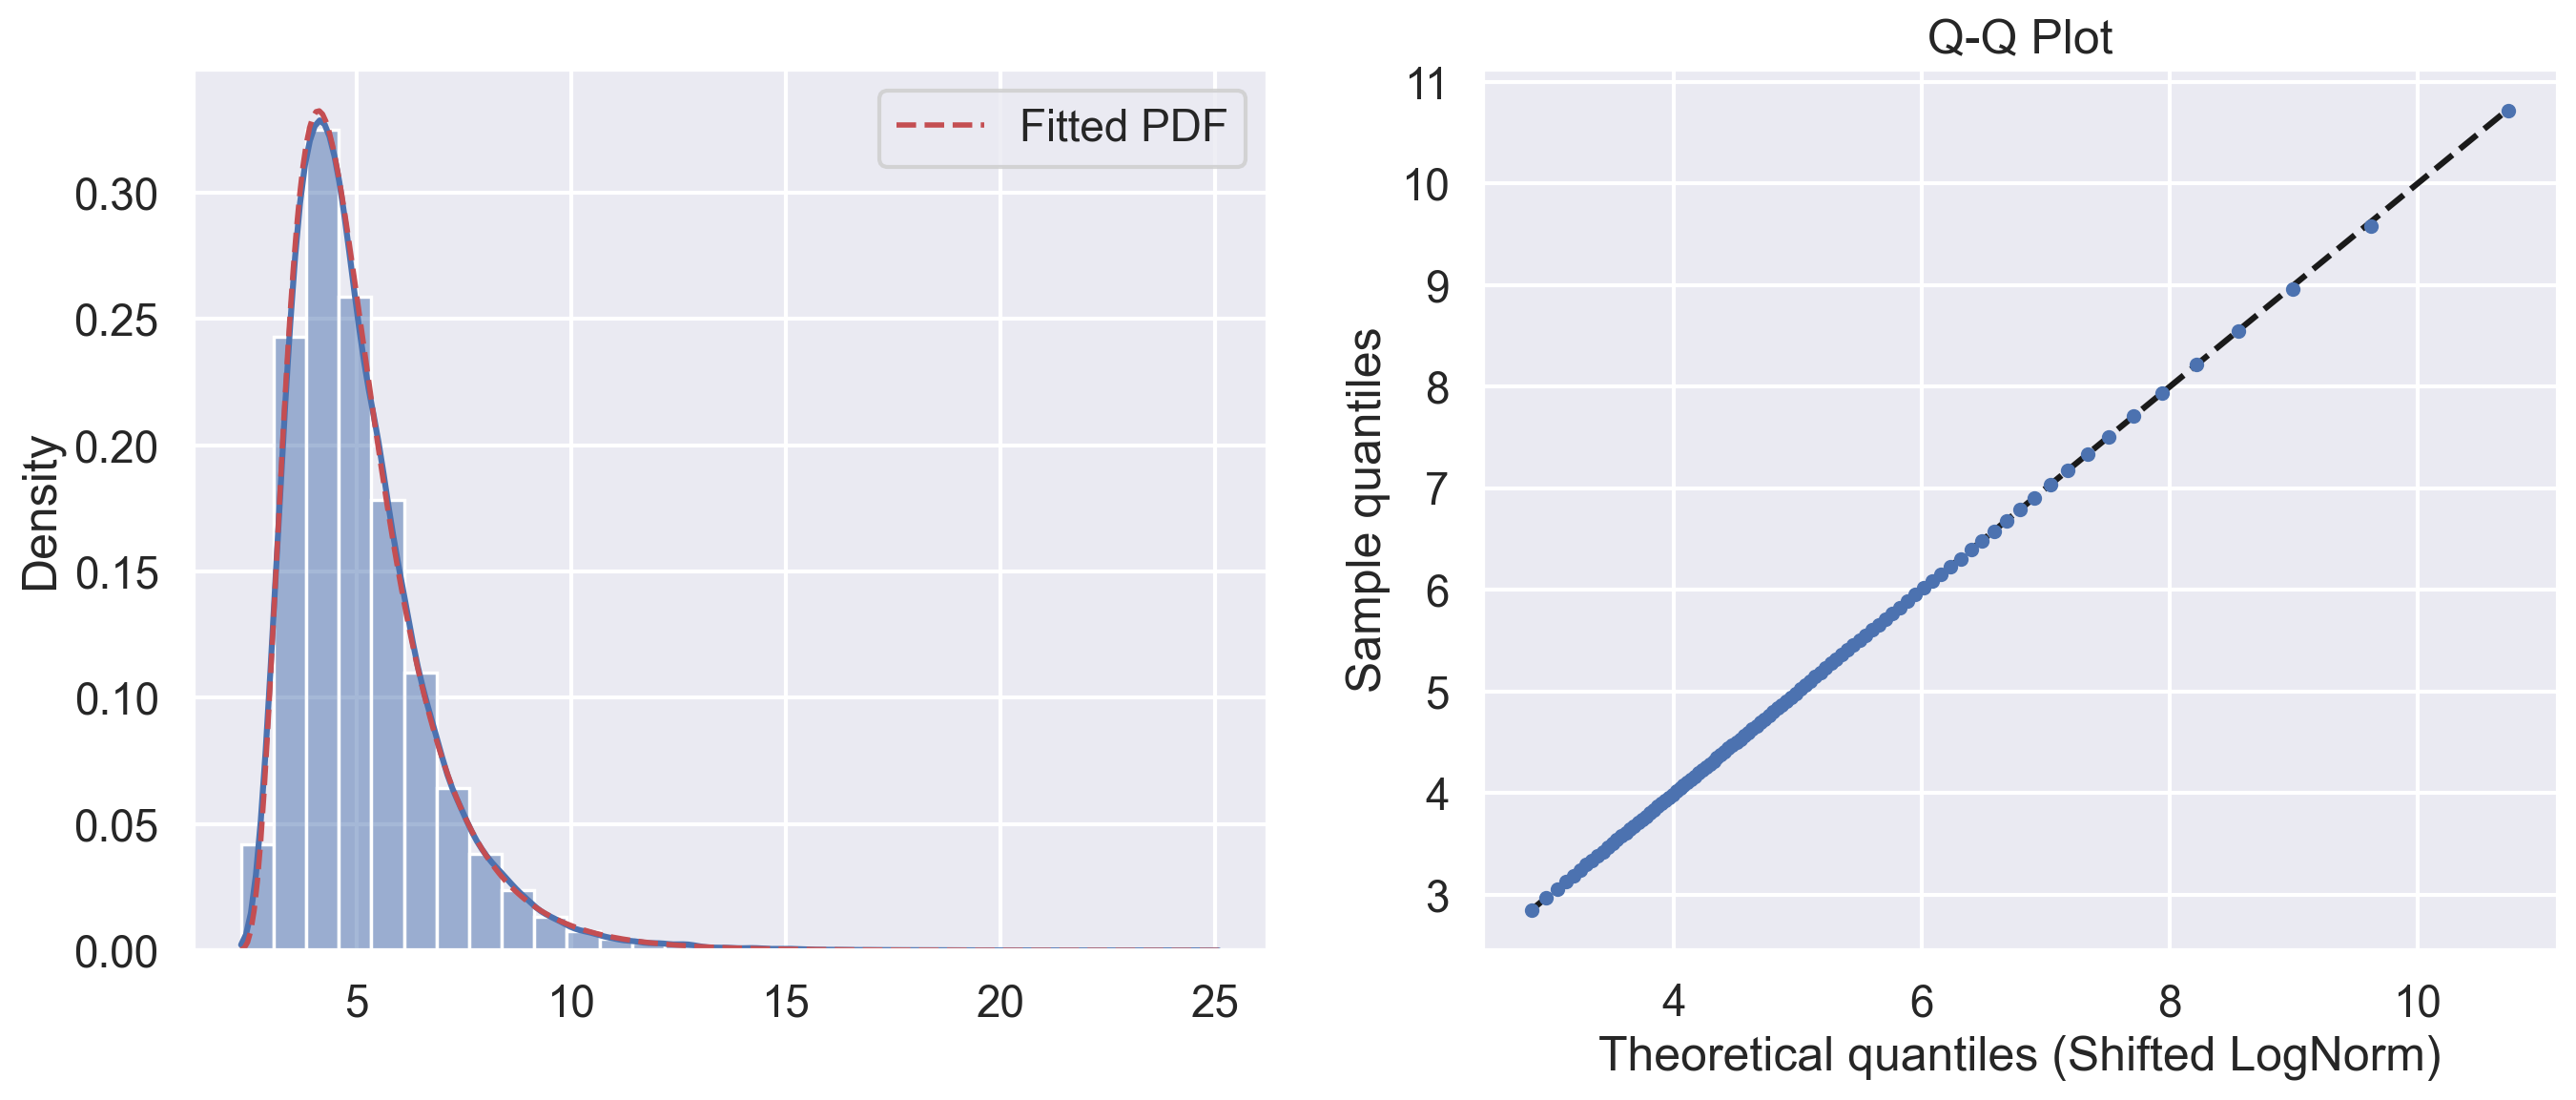

In [73]:
fig, ax = plt.subplots(1, 2, figsize=(2 * 8, 6))
sns.histplot(data, bins=30, kde=True, ax=ax[0], stat="density")
ax[0].plot(x_grid, pdf_vals, "r--", lw=2, label="Fitted PDF")
ax[0].legend()

quantiles = np.linspace(1e-2, 1 - 1e-2, 100)
lognorm_ppf = stats.lognorm.ppf(quantiles, s=sigma, scale=scale, loc=shift)

# Q-Q plot
ax[1].plot(lognorm_ppf, lognorm_ppf, "k--")
ax[1].plot(lognorm_ppf, np.quantile(data, quantiles), ".")
ax[1].set_xlabel("Theoretical quantiles (Shifted LogNorm)")
ax[1].set_ylabel("Sample quantiles")
ax[1].set_title("Q-Q Plot")

plt.show()

Now, do the same for the VIX

In [77]:
fitted_params = {}

for T_i in spx_expiries:
    vix_Ti = qrh_sim[T_i]["vix"]
    s, loc, scale = stats.lognorm.fit(vix_Ti)
    fitted_params[T_i] = {"shape": s, "location": loc, "scale": scale}

    print(f"Fitted parameters: (T={T_i:<.4f})")
    print(f"  Shape (sigma): {s:<.4f}")
    print(f"  Location (shift): {loc:<.4f}")
    print(f"  Scale (scale): {scale:<.4f}")

Fitted parameters: (T=0.0192)
  Shape (sigma): 0.5208
  Location (shift): 0.1463
  Scale (scale): 0.0345
Fitted parameters: (T=0.0383)
  Shape (sigma): 0.5616
  Location (shift): 0.1446
  Scale (scale): 0.0422
Fitted parameters: (T=0.0548)
  Shape (sigma): 0.5635
  Location (shift): 0.1433
  Scale (scale): 0.0481
Fitted parameters: (T=0.0767)
  Shape (sigma): 0.5867
  Location (shift): 0.1446
  Scale (scale): 0.0517


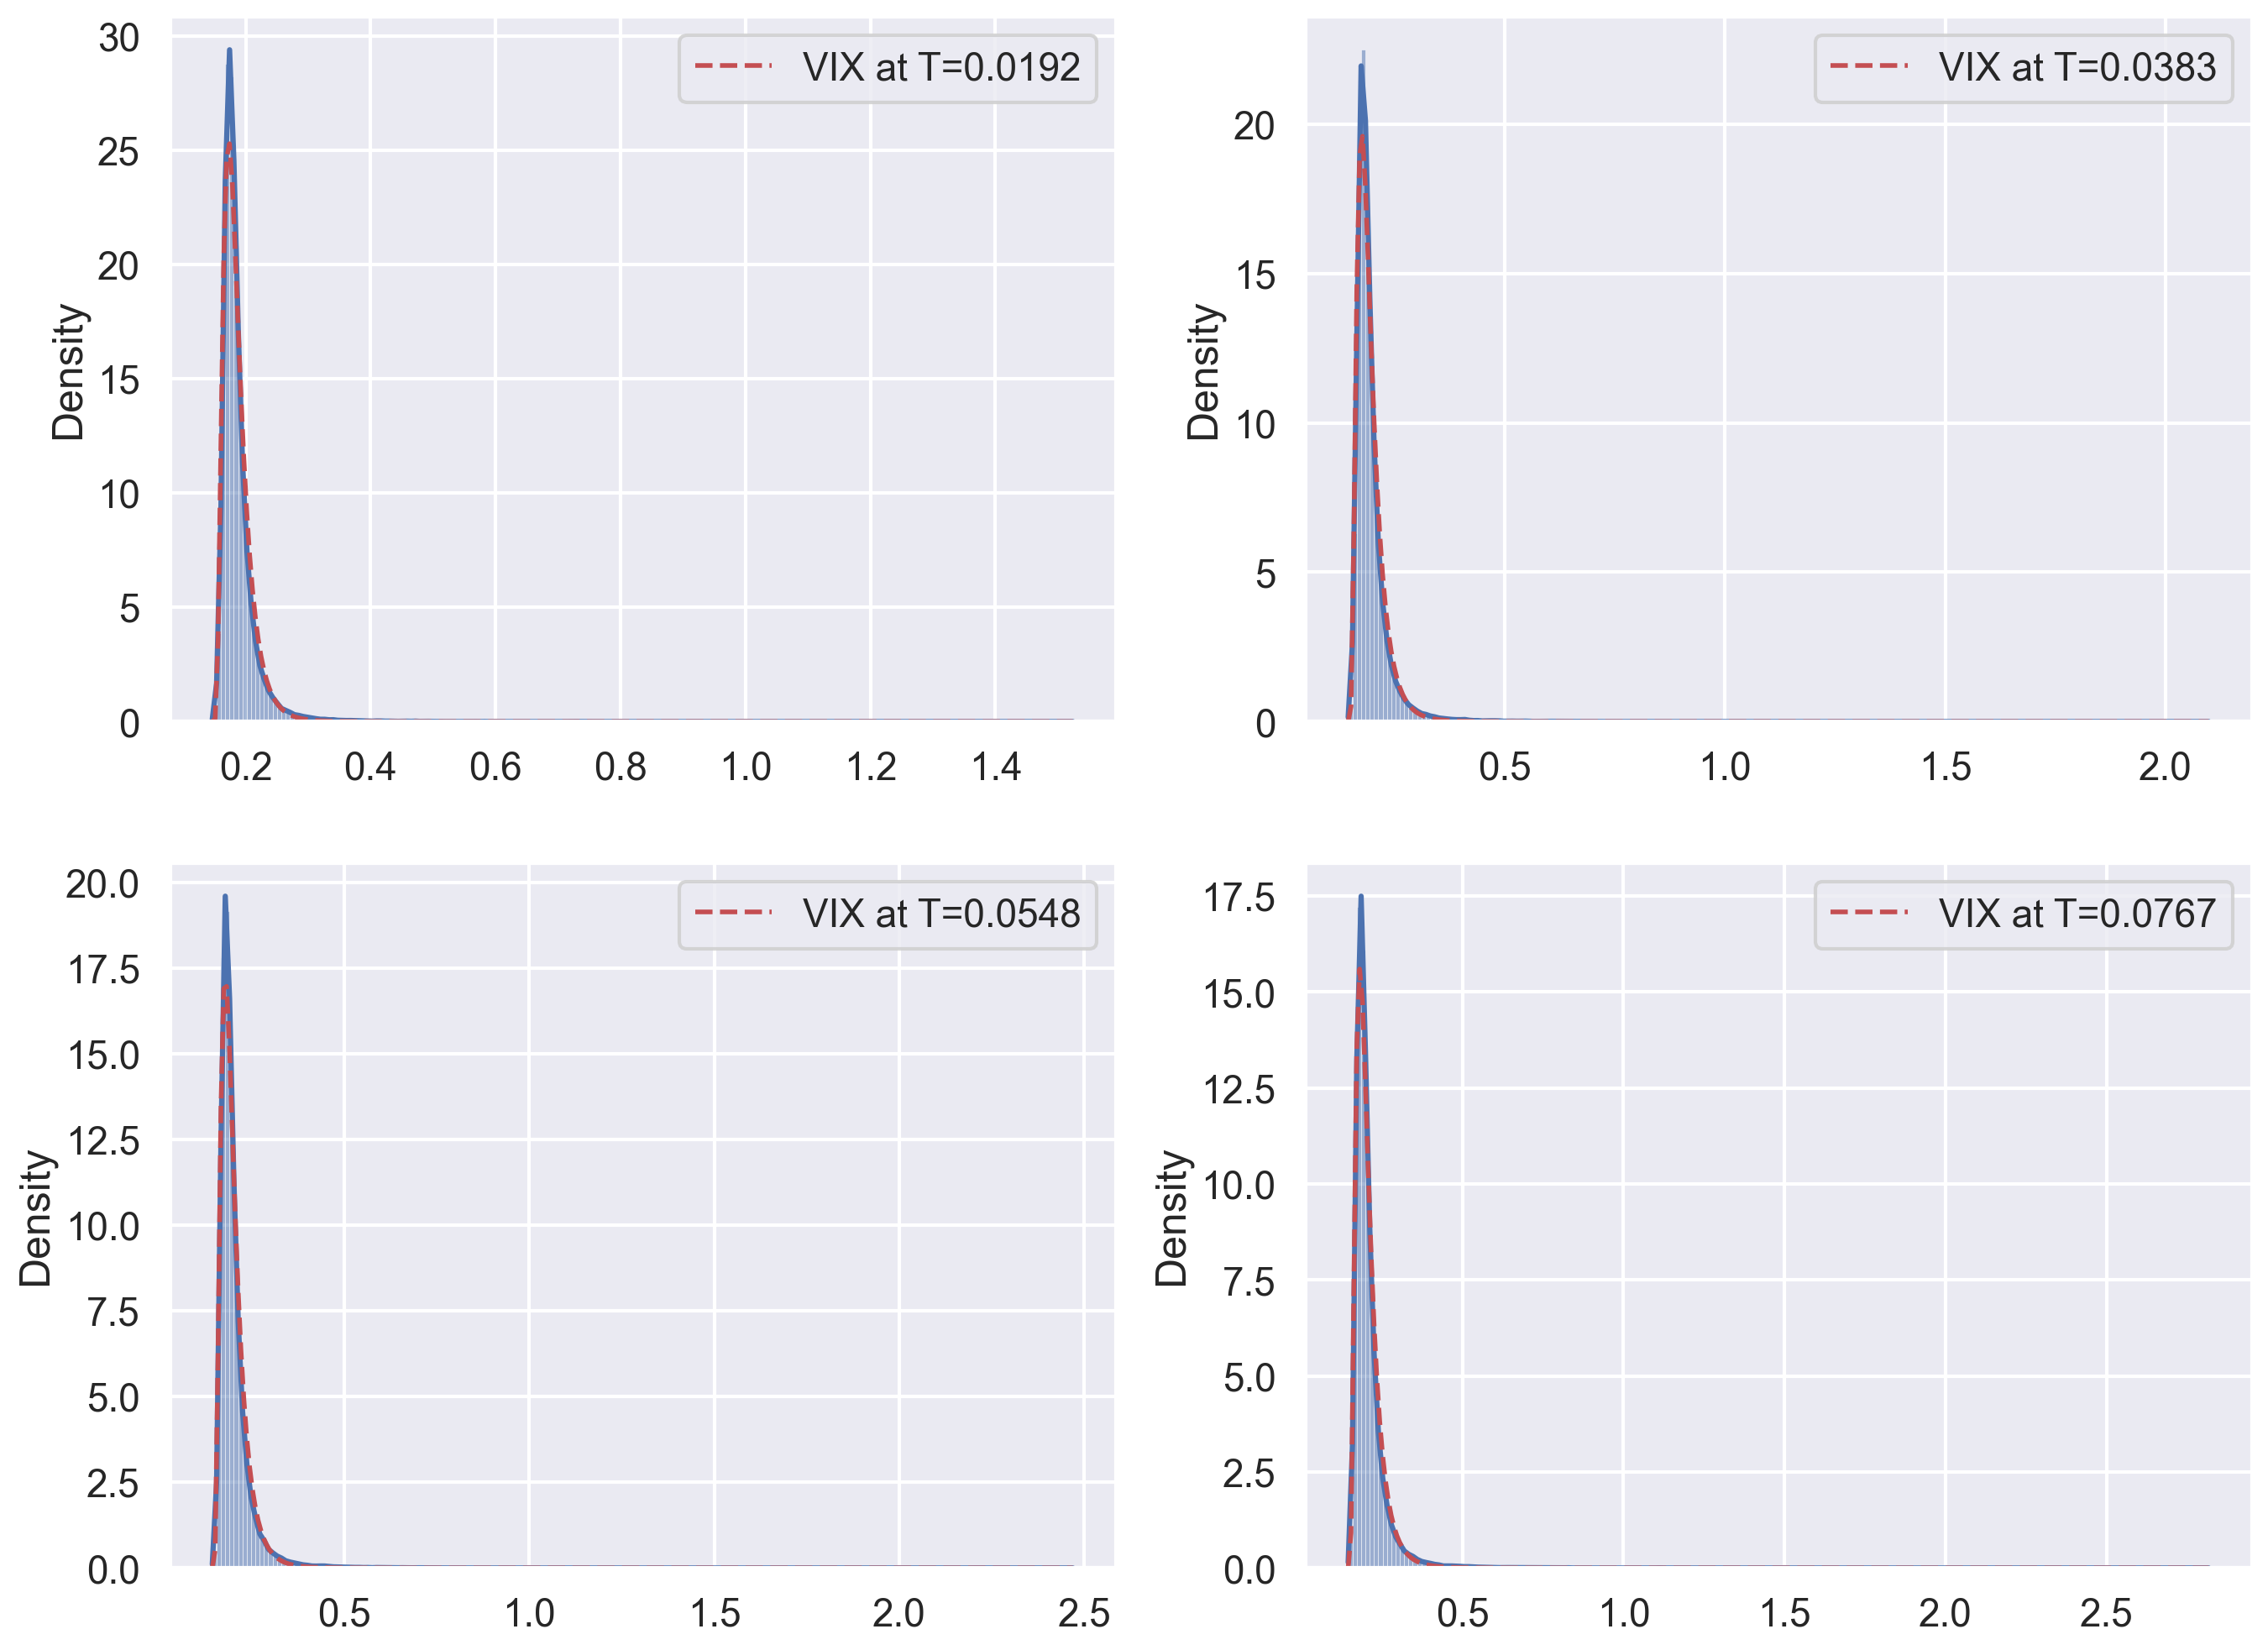

In [85]:
fig, ax = plt.subplots(2, 2, figsize=(2 * 8, 2 * 6))
for i, T_i in enumerate(spx_expiries):
    row, col = divmod(i, 2)
    ax_i = ax[row, col]
    vix_Ti = qrh_sim[T_i]["vix"]
    shape_i = fitted_params[T_i]["shape"]
    loc_i = fitted_params[T_i]["location"]
    scale_i = fitted_params[T_i]["scale"]

    x_grid_vix = np.linspace(np.min(vix_Ti), np.max(vix_Ti), 301)
    sns.histplot(vix_Ti, bins=200, ax=ax_i, kde=True, stat="density")
    ax_i.plot(
        x_grid_vix,
        stats.lognorm.pdf(x_grid_vix, shape_i, loc_i, scale_i),
        "r--",
        lw=2,
        label=f"VIX at T={T_i:<.4f}",
    )
    ax_i.legend()
plt.show()

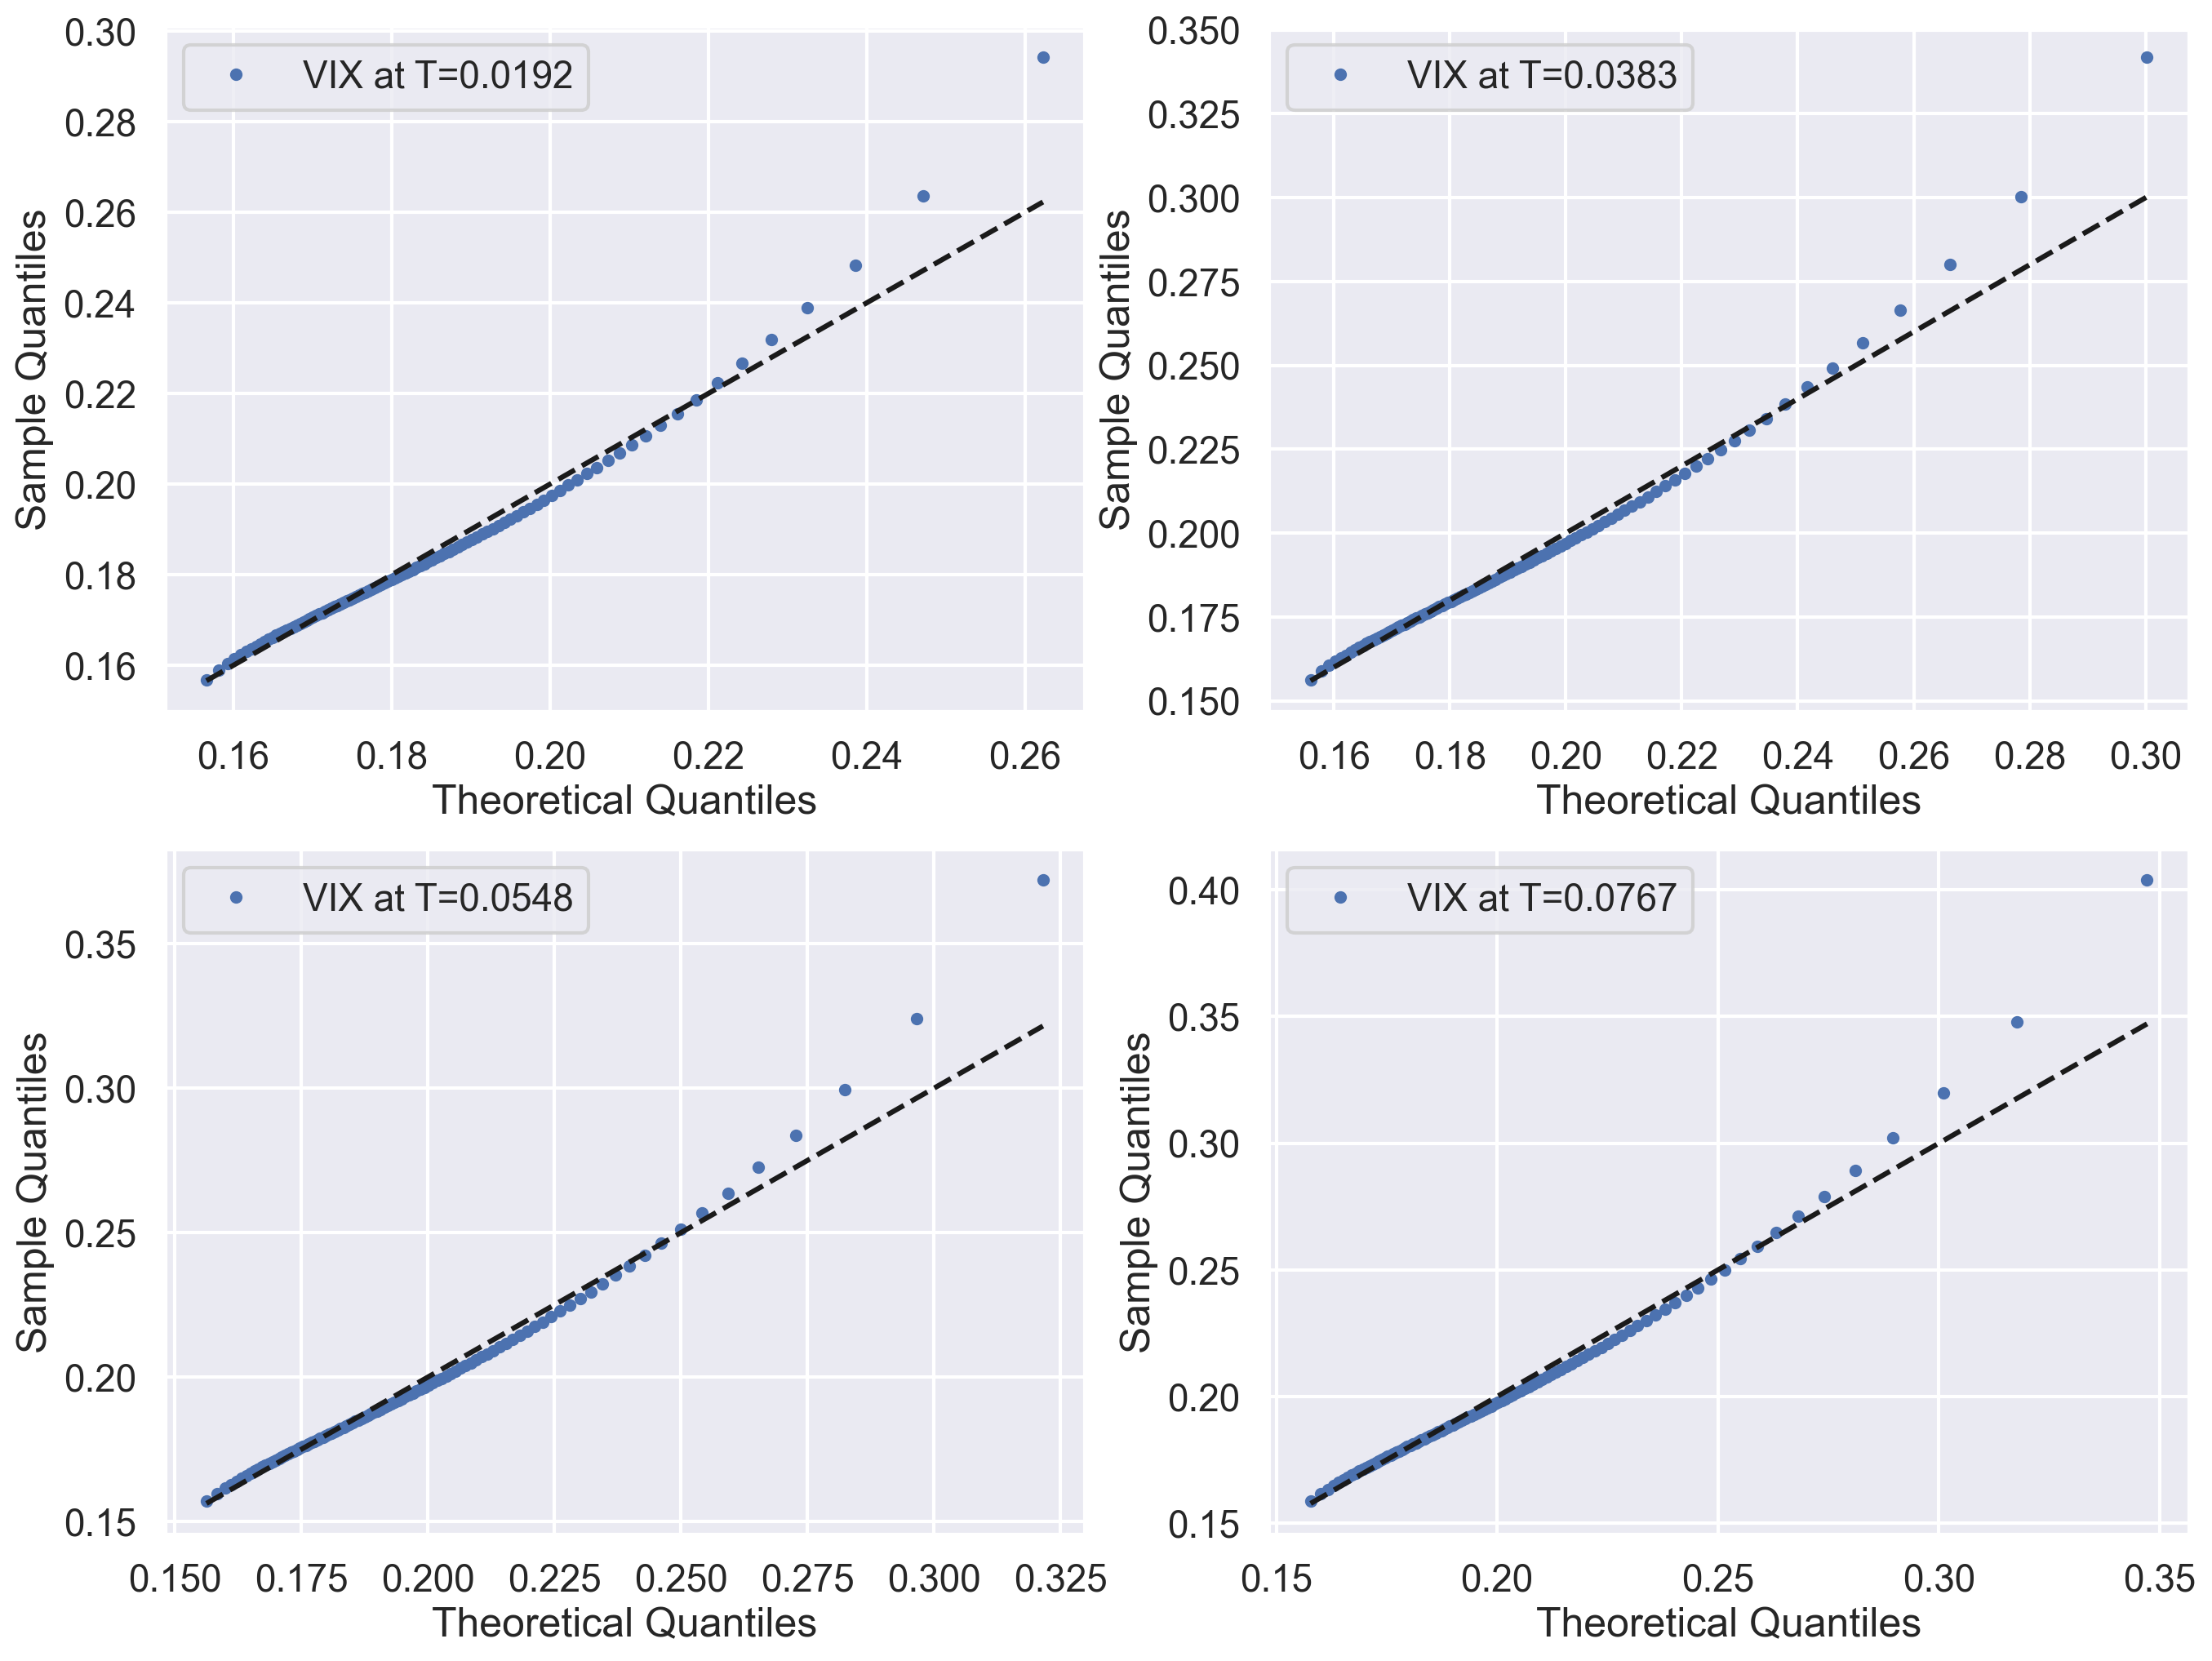

In [84]:
# Q-Q plot

quantiles = np.linspace(1e-2, 1 - 1e-2, 101)

fig, ax = plt.subplots(2, 2, figsize=(2 * 8, 2 * 6))
for i, T_i in enumerate(spx_expiries):
    row, col = divmod(i, 2)
    ax_i = ax[row, col]
    vix_Ti = qrh_sim[T_i]["vix"]
    shape_i = fitted_params[T_i]["shape"]
    loc_i = fitted_params[T_i]["location"]
    scale_i = fitted_params[T_i]["scale"]

    # plot
    lognorm_ppf = stats.lognorm.ppf(quantiles, shape_i, loc_i, scale_i)
    ax_i.plot(
        lognorm_ppf,
        np.quantile(vix_Ti, q=quantiles),
        ".",
        label=f"VIX at T={T_i:<.4f}",
    )
    ax_i.plot(lognorm_ppf, lognorm_ppf, "k--")
    ax_i.legend()
    ax_i.set_xlabel("Theoretical Quantiles")
    ax_i.set_ylabel("Sample Quantiles")
plt.show()